# 02 · Definisi Label Model A (Hujan)

**Pertanyaan:** berapa ambang curah hujan untuk label Model A, dan apakah label itu cukup sering muncul di data ERA5 untuk dilatih?

## Ambang resmi BMKG

| Dokumen | Isi | Status |
|---|---|---|
| [Perka BMKG KEP.009/2010](https://jdih.bmkg.go.id/common/dokumen/Prosedur%20Standar%20Operasional%20Pelaksanaan%20Peringatan%20Dini,Pelaporan,&%20Diseminasi%20Informasi%20Cuaca%20Ekstrim.pdf) | *"Hujan Lebat adalah hujan dengan intensitas paling rendah 50 mm/24 jam dan/atau 20 mm/jam"* | Dicabut |
| [Peraturan BMKG No. 9/2022](https://jdih.bmkg.go.id/storage/common/dokumen/2022peraturanbmkg009.pdf) | Jenis dan tingkatan peringatan dini cuaca ekstrem (waspada/siaga/awas). **Tidak mencantumkan angka mm.** Pasal 55 mencabut Perka 2010 | Berlaku |
| [Surat Peringatan Dini Cuaca & Iklim BMKG, 10 Juli 2026](https://staklim-kalsel.bmkg.go.id/wp-content/uploads/2026/07/Kalsel-Dasarian-II-Juli-2026-TTE_signed.pdf) | *Tabel Intensitas Hujan, CH perhari*: ringan 0,5–20 · sedang 20–50 · **lebat 50–100** · sangat lebat 100–150 · ekstrem >150 mm | Praktik terkini |

Kategori ini disimpan di `pipeline/rainfall.py`.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from pipeline.ingest.http import make_session
from pipeline.ingest.openmeteo import fetch_daily_archive
from pipeline.locations import PILOT_LOCATIONS
from pipeline.rainfall import MODEL_A_THRESHOLD_MM

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cache = ROOT / "data/raw/open-meteo/archive_daily_era5_2017_2026.json"
if not cache.exists():
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(fetch_daily_archive(make_session(), PILOT_LOCATIONS, "2017-01-01", "2026-10-31")))
raw = json.loads(cache.read_text())
df = pd.concat([
    pd.DataFrame({"kota": loc.slug, "tanggal": pd.to_datetime(x["daily"]["time"]), "mm": x["daily"]["precipitation_sum"]})
    for loc, x in zip(PILOT_LOCATIONS, raw)
], ignore_index=True)
print(f"{len(df):,} kota-hari, {df.tanggal.min():%Y-%m-%d} s.d. {df.tanggal.max():%Y-%m-%d}, nilai kosong: {df.mm.isna().sum()}")

28,728 kota-hari, 2017-01-01 s.d. 2026-10-31, nilai kosong: 0


## 1. Hujan ≥50 mm hampir tidak ada di ERA5

ERA5 adalah *reanalysis* dengan grid ±25 km, sehingga hujan konvektif lokal ikut diratakan. Stasiun BMKG mencatat hujan ≥50 mm beberapa kali per musim hujan, tetapi ERA5 untuk Jakarta hanya mencatat 7 hari dalam hampir 10 tahun.

In [2]:
by_city = df.groupby("kota").mm.agg(
    hari="size",
    hari_ge50=lambda s: int((s >= 50).sum()),
    porsi_ge50=lambda s: f"{(s >= 50).mean():.2%}",
    hari_ge20=lambda s: int((s >= 20).sum()),
    porsi_ge20=lambda s: f"{(s >= 20).mean():.1%}",
    p99_mm=lambda s: round(s.quantile(0.99), 1),
)
by_city.loc["total"] = [by_city.hari.sum(), by_city.hari_ge50.sum(), f"{(df.mm >= 50).mean():.2%}",
                        by_city.hari_ge20.sum(), f"{(df.mm >= 20).mean():.1%}", round(df.mm.quantile(0.99), 1)]
by_city

,hari,hari_ge50,porsi_ge50,hari_ge20,porsi_ge20,p99_mm
kota,,,,,,
bandung,3591,25,0.70%,314,8.7%,43.1
bogor,3591,11,0.31%,262,7.3%,37.1
jakarta,3591,7,0.19%,148,4.1%,30.5
makassar,3591,47,1.31%,369,10.3%,53.9
medan,3591,25,0.70%,356,9.9%,45.4
semarang,3591,25,0.70%,283,7.9%,42.0
surabaya,3591,5,0.14%,142,4.0%,30.4
yogyakarta,3591,35,0.97%,297,8.3%,48.0
total,28728,180,0.63%,2171,7.6%,42.2


## 2. Ambang ≥20 mm: musiman dan cukup sering

Ambang 20 mm adalah batas bawah kategori **sedang** BMKG. Label dibaca sebagai *"hujan sedang ke atas"*, bukan *"hujan lebat"*.

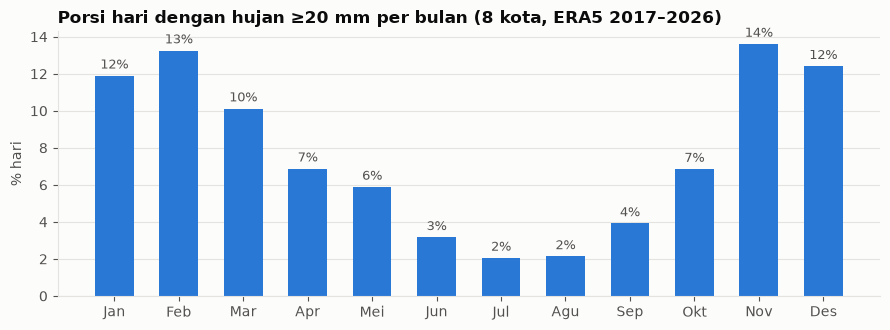

In [3]:
SURFACE, INK, INK2, GRID, BAR = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

df["positif"] = df.mm >= MODEL_A_THRESHOLD_MM
monthly = df.groupby(df.tanggal.dt.month).positif.mean() * 100
names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(names, monthly.values, width=0.6, color=BAR)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in monthly.values], padding=3, color=INK2, fontsize=9)
ax.set_title(f"Porsi hari dengan hujan ≥{MODEL_A_THRESHOLD_MM:.0f} mm per bulan (8 kota, ERA5 2017–2026)", loc="left", fontweight="bold")
ax.set_ylabel("% hari"); ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [4]:
per_year = df.pivot_table(index=df.tanggal.dt.year.rename("tahun"), columns="kota", values="positif", aggfunc="sum")
per_year["total"] = per_year.sum(axis=1)
per_year

kota,bandung,bogor,jakarta,makassar,medan,semarang,surabaya,yogyakarta,total
tahun,,,,,,,,,
2017,38,33,17,35,43,39,17,30,252
2018,27,23,4,33,28,19,14,21,169
2019,29,23,13,26,19,27,13,25,175
2020,41,36,24,39,45,35,16,41,277
2021,33,27,22,57,29,31,17,38,254
2022,33,19,12,47,50,26,15,46,248
2023,21,16,7,23,37,24,12,16,156
2024,30,36,17,33,48,30,15,27,236
2025,45,38,20,48,37,38,18,40,284


In [5]:
split = pd.cut(df.tanggal.dt.year, bins=[2016, 2023, 2024, 2026], labels=["latih 2017–2023", "validasi 2024", "uji 2025–Okt 2026"])
df.groupby(split, observed=True).positif.agg(kota_hari="size", positif="sum", porsi="mean").assign(porsi=lambda t: t.porsi.map("{:.1%}".format))

,kota_hari,positif,porsi
tanggal,,,
latih 2017–2023,20448,1531,7.5%
validasi 2024,2928,236,8.1%
uji 2025–Okt 2026,5352,404,7.5%


## 3. Keputusan

- **Label Model A:** curah hujan harian ERA5 (00–24 WIB) **≥ 20 mm**, yaitu kategori BMKG *sedang ke atas*. Nama di UI: **"Peluang hujan sedang–lebat (≥20 mm)"**, bukan "hujan lebat".
- **Evaluasi tambahan:** ≥50 mm tetap dilaporkan (recall pada 180 kejadian), tanpa jadi target latih.
- **Split waktu:** latih 2017–2023, validasi 2024, uji 2025–Okt 2026. Historical Forecast tersedia sejak awal 2017, jadi fitur prakiraan tersedia untuk seluruh periode.

**Keterbatasan yang dinyatakan:** ERA5 bukan pengukuran stasiun dan meremehkan hujan ekstrem. Model memprediksi hujan rata-rata area ±25 km, bukan hujan di satu titik. Validasi dengan data stasiun BMKG bisa menjadi pengembangan lanjutan.